# 02 死亡模型：生命表、高龄平滑与 Lee–Carter 随机预测

**这一步要回答的问题**：未来每个年龄的人活过一年的概率是多少？会怎样改善？不确定性有多大？

在人口债券的比喻里，死亡率决定了两件事：
- **“入场”前的损耗**：出生的人有多少能活到 20 岁进入劳动力市场；
- **“兑付期”的长度**：活到 65 岁的人平均还要领多少年养老金（65 岁余寿 $e_{65}$）。

旧模型的问题：直接用 2020 年普查的 $1-D/P$ 当存活率、强行截断在 0.90–0.9999、未来不变。
本 notebook 依次替换为：**标准生命表 → Kannisto 高龄平滑 → Lee–Carter 随机预测**。

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iop import census, coverage, ddm, fertility, leecarter, lifetable, official, wpp
from iop.plotting import COLORS, SEX_STYLE, YEAR_STYLE, fan, percentiles, pyramid, setup

setup()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
from dataclasses import replace

N_SIMS = 500
SEED = 20261018

## 1. 生命表：把死亡率变成“存活账本”

生命表从中心死亡率 $m_x$ 出发，追踪一个假想的 10 万人出生队列：

| 记号 | 含义 | 债券类比 |
|---|---|---|
| $q_x = \dfrac{m_x}{1+(1-a_x)m_x}$ | $x$ 岁到 $x+1$ 岁的死亡概率 | 每期违约率 |
| $l_x$ | 活到 $x$ 岁的比例 | 存续本金 |
| $L_x$ | $x$ 岁这一年存活的人年数 | 每期计息本金 |
| $e_x = T_x / l_x$ | $x$ 岁时的预期余寿 | 剩余期限 |

$a_x$ 是死者在当年内平均活过的时间，0 岁用 Andreev–Kingkade (2015) 公式（婴儿死亡集中在出生后不久），其他年龄取 0.5。

下面用 notebook 01 校正后的 2020 年死亡率（口径 B，对齐官方 e0）：

In [2]:
adj = {y: coverage.adjusted_mortality(y, target="e0") for y in census.YEARS}
lt20 = {s: lifetable.life_table(adj[2020]["mx"][s], s) for s in ("male", "female")}
lt20["female"].loc[[0, 1, 5, 20, 40, 60, 65, 80, 90, 100, 110]]

,mx,qx,ax,lx,dx,Lx,Tx,ex
age,,,,,,,,
0,4.907e-03,4.887e-03,0.139,1.000e+00,4.887e-03,9.958e-01,8.088e+01,80.880
1,8.969e-04,8.965e-04,0.500,9.951e-01,8.921e-04,9.947e-01,7.988e+01,80.276
5,1.984e-04,1.984e-04,0.500,9.933e-01,1.970e-04,9.932e-01,7.591e+01,76.424
20,2.995e-04,2.994e-04,0.500,9.899e-01,2.964e-04,9.897e-01,6.103e+01,61.656
40,8.254e-04,8.251e-04,0.500,9.814e-01,8.098e-04,9.810e-01,4.131e+01,42.087
60,5.392e-03,5.378e-03,0.500,9.374e-01,5.041e-03,9.349e-01,2.200e+01,23.469
65,9.249e-03,9.206e-03,0.500,9.055e-01,8.336e-03,9.013e-01,1.739e+01,19.200
80,5.821e-02,5.657e-02,0.500,6.295e-01,3.561e-02,6.117e-01,5.374e+00,8.537
90,1.620e-01,1.499e-01,0.500,2.312e-01,3.465e-02,2.139e-01,1.051e+00,4.547


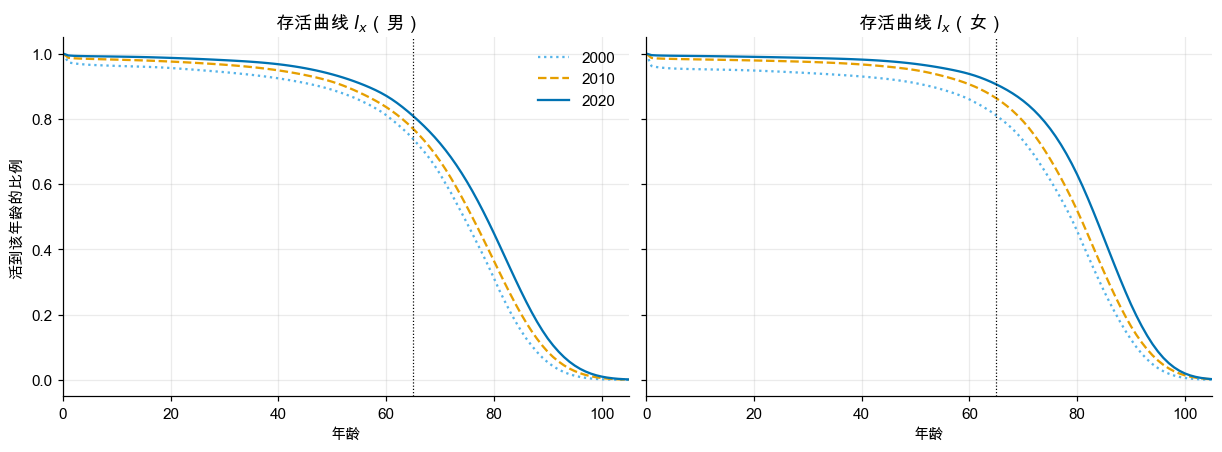

e0  活到20岁  活到65岁  e65（兑付期长度）
性别 年份                                   
男  2000  69.63  0.956  0.738      13.566
   2010  72.38  0.975  0.769      14.716
   2020  75.37  0.987  0.809      16.281
女  2000  73.33  0.948  0.810      16.293
   2010  77.37  0.979  0.863      17.296
   2020  80.88  0.990  0.906      19.200

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
rows = []
for ax, sex in zip(axes, ("male", "female")):
    for year in census.YEARS:
        lt = lifetable.life_table(adj[year]["mx"][sex], sex)
        st = YEAR_STYLE[year]
        ax.plot(lt.index, lt["lx"], color=st["color"], ls=st["ls"], label=str(year))
        rows.append({"性别": SEX_STYLE[sex]["label"], "年份": year, "e0": lt.loc[0, "ex"], "活到20岁": lt.loc[20, "lx"],
                     "活到65岁": lt.loc[65, "lx"], "e65（兑付期长度）": lt.loc[65, "ex"]})
    ax.axvline(65, color=COLORS["black"], lw=0.8, ls=":")
    ax.set(title=f"存活曲线 $l_x$（{SEX_STYLE[sex]['label']}）", xlabel="年龄", xlim=(0, 105))
axes[0].set_ylabel("活到该年龄的比例")
axes[0].legend()
plt.show()
pd.DataFrame(rows).set_index(["性别", "年份"])

存活曲线越来越“方”（人口学叫 **矩形化**）：死亡越来越集中在高龄。对债券模型而言，
**活到 65 岁“兑付期”的人越来越多，兑付期也越来越长**——这正是养老压力上升的生物学来源。

## 2. 高龄平滑：Kannisto 模型

90 岁以上的普查数据很不可靠：年龄夸报（把 88 岁报成 90 岁）、死亡漏报、人数太少导致随机波动大。
直接使用会出现死亡率在 95 岁后**反而下降**的不合理现象。

**Kannisto 模型**是人类死亡数据库（HMD）的标准做法，假设高龄死亡力服从 logistic 曲线：
$$
\mu(x) = \frac{a\,e^{b(x-80)}}{1 + a\,e^{b(x-80)}}
$$
它在 80–90 岁像 Gompertz 指数增长，更高龄时逐渐趋平（“死亡率减速”，已被大量长寿研究证实）。
用 80–94 岁的数据拟合，替换 90 岁以上并延伸到 110 岁。

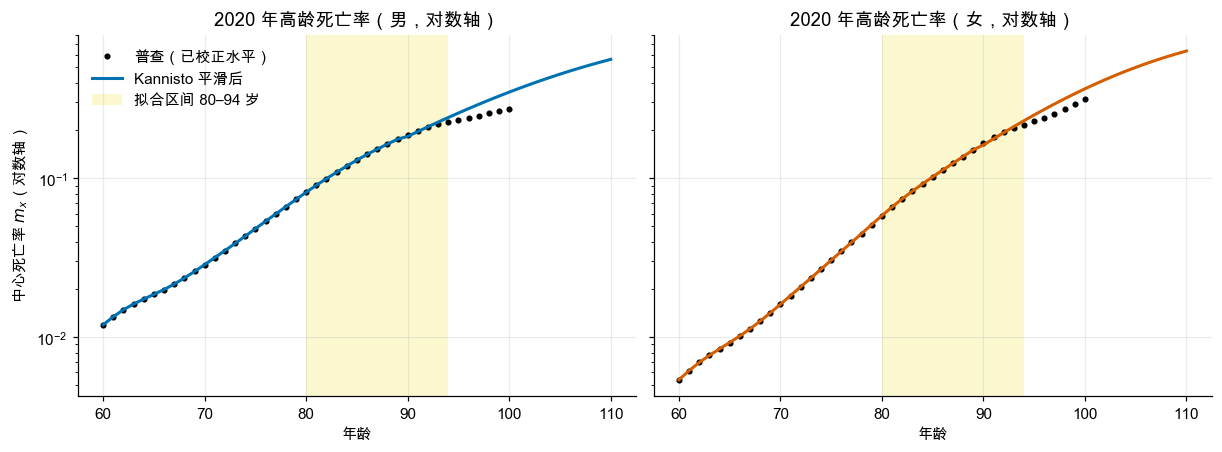

In [4]:
r = adj[2020]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, sex in zip(axes, ("male", "female")):
    raw_scaled = r["raw"][sex] * r["factors"][f"adult_{sex}"]
    closed = r["mx"][sex]
    ax.semilogy(raw_scaled.loc[60:100].index, raw_scaled.loc[60:100], "o", ms=3, color=COLORS["black"], label="普查（已校正水平）")
    ax.semilogy(closed.loc[60:110].index, closed.loc[60:110], color=SEX_STYLE[sex]["color"], lw=2, label="Kannisto 平滑后")
    ax.axvspan(80, 94, color=COLORS["yellow"], alpha=0.25, lw=0, label="拟合区间 80–94 岁")
    ax.set(title=f"2020 年高龄死亡率（{SEX_STYLE[sex]['label']}，对数轴）", xlabel="年龄")
axes[0].set_ylabel("中心死亡率 $m_x$（对数轴）")
axes[0].legend()
plt.show()

## 3. Lee–Carter：死亡率怎样随时间改善

只有三次普查（3 个时间点）无法可靠估计改善速度，所以这里用 **WPP 1990–2019 年逐年单岁死亡率**（30 年 × 90 个年龄）来估计“改善规律”，
再把这个规律嫁接到 2020 年普查校正后的死亡率上（见第 5 节）。

$$
\log m(x,t) = a(x) + b(x)\,k(t) + \varepsilon(x,t)
$$

- $a(x)$：各年龄的平均死亡水平；
- $k(t)$：**一个**随时间变化的总体死亡指数，所有年龄共享；
- $b(x)$：各年龄对 $k(t)$ 的敏感度（$b(x)$ 大 = 这个年龄改善快）。

估计方法：对 $\log m - a$ 的矩阵做**奇异值分解（SVD）**取第一主成分；再逐年微调 $k(t)$，使模型死亡总数等于实际死亡总数（Lee–Carter 原文的第二步）。

拟合排除了 2020 年之后：2022 年底到 2023 年初的新冠感染高峰是一次性冲击，不代表长期趋势。

In [5]:
D, E = wpp.deaths(), wpp.exposure()
LC_AGES = list(range(0, 90))

def fit_lc(sex, years):
    log_m = np.log(wpp.mortality_rates()[sex].loc[LC_AGES, years])
    deaths = D[sex].unstack("year").loc[LC_AGES, years]
    exposure = E[sex].unstack("year").loc[LC_AGES, years]
    return leecarter.fit(log_m, deaths, exposure)

FIT_YEARS = list(range(1990, 2020))
lc_models = {s: fit_lc(s, FIT_YEARS) for s in ("male", "female")}
pd.DataFrame({SEX_STYLE[s]["label"]: {"第一主成分解释方差": m.explained, "k 年漂移 d": m.drift, "k 年波动 σ": m.sigma}
              for s, m in lc_models.items()})

,男,女
第一主成分解释方差,0.970,0.964
k 年漂移 d,-2.213,-2.612
k 年波动 σ,1.435,0.746


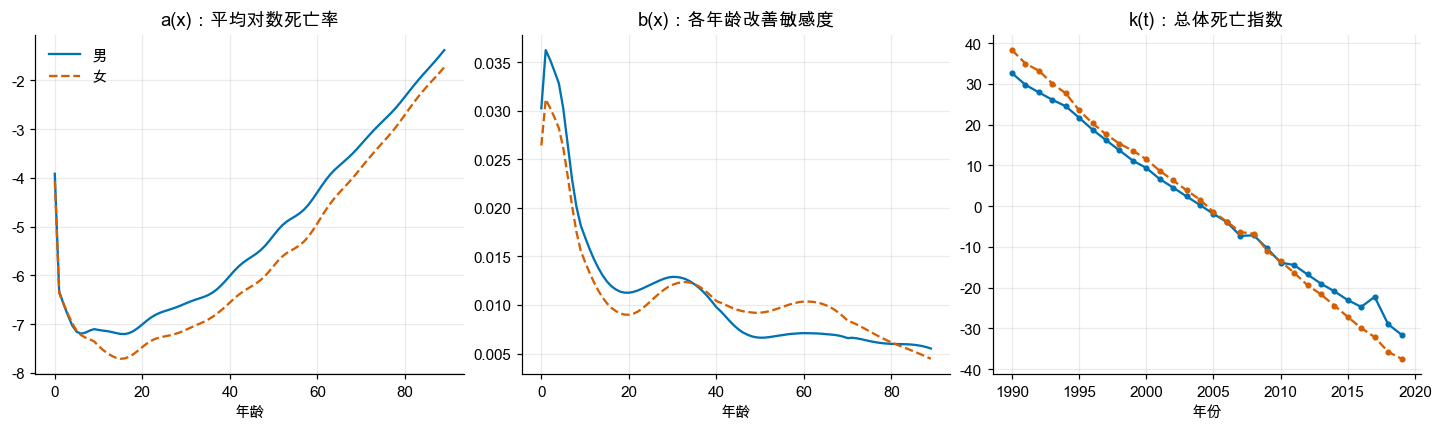

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for sex, m in lc_models.items():
    st = SEX_STYLE[sex]
    axes[0].plot(m.ax.index, m.ax, color=st["color"], ls=st["ls"], label=st["label"])
    axes[1].plot(m.bx.index, m.bx, color=st["color"], ls=st["ls"], label=st["label"])
    axes[2].plot(m.kt.index, m.kt, color=st["color"], ls=st["ls"], marker=".", label=st["label"])
axes[0].set(title="a(x)：平均对数死亡率", xlabel="年龄")
axes[1].set(title="b(x)：各年龄改善敏感度", xlabel="年龄")
axes[2].set(title="k(t)：总体死亡指数", xlabel="年份")
axes[0].legend()
plt.show()

**读图**：
- 第一主成分解释了约 96%–97% 的变化——用一个指数 $k(t)$ 描述死亡率变化是合理的近似。
- $k(t)$ 近乎直线下降，所以用**带漂移的随机游走**预测：$k(t+1) = k(t) + d + e_t$。
- $b(x)$ 在儿童期最大（儿童死亡率下降最快），在老年期较小。

## 4. 回测：用 1990–2009 年预测 2010–2023 年

这是检验预测方法最直接的办法：假装站在 2009 年，只用之前的数据拟合，然后看预测区间能不能盖住后来真实发生的值。

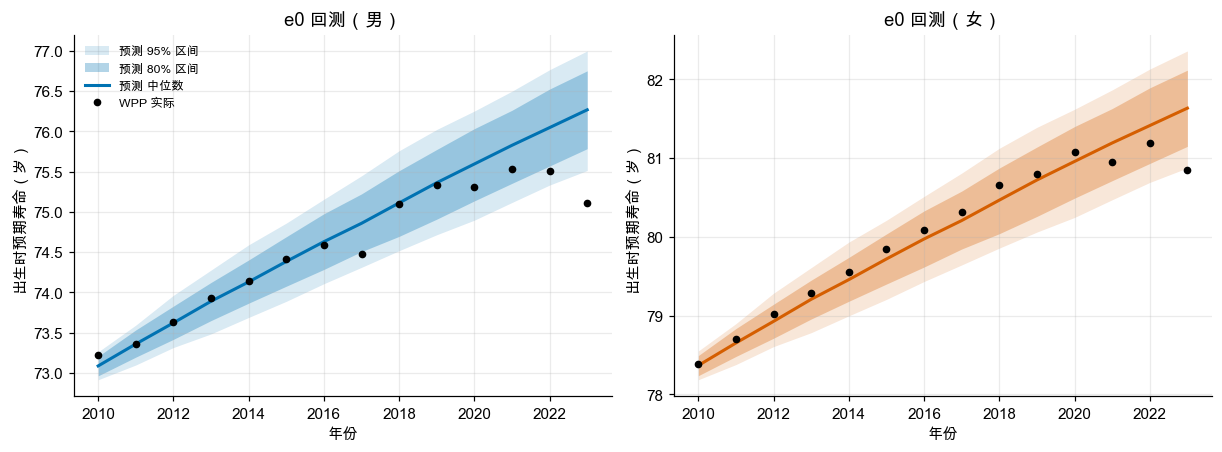

,2010–2019 落入95%区间,2019 预测中位,2019 实际,2023 预测中位,2023 实际
性别,,,,,
男,10/10,75.361,75.339,76.266,75.105
女,10/10,80.721,80.802,81.634,80.846


In [7]:
BT_YEARS = list(range(1990, 2010))
H = 14
test_years = np.arange(2010, 2010 + H)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
rows = []
for ax, sex in zip(axes, ("male", "female")):
    m = fit_lc(sex, BT_YEARS)
    sims = leecarter.e0_paths(m, sex, H, n_sims=N_SIMS, seed=SEED)
    f = percentiles(sims, test_years)
    actual = pd.Series([lifetable.e0(lifetable.kannisto_close(wpp.mortality_rates()[sex][y], fit_ages=range(80, 90)), sex) for y in test_years], index=test_years)
    fan(ax, f, SEX_STYLE[sex]["color"], "预测")
    ax.plot(actual.index, actual, "o", color=COLORS["black"], ms=4, label="WPP 实际")
    ax.set(title=f"e0 回测（{SEX_STYLE[sex]['label']}）", xlabel="年份", ylabel="出生时预期寿命（岁）")
    inside = (actual >= f["p2.5"]) & (actual <= f["p97.5"])
    rows.append({"性别": SEX_STYLE[sex]["label"], "2010–2019 落入95%区间": f"{inside.loc[:2019].sum()}/10",
                 "2019 预测中位": f.loc[2019, "p50"], "2019 实际": actual.loc[2019],
                 "2023 预测中位": f.loc[2023, "p50"], "2023 实际": actual.loc[2023]})
axes[0].legend(fontsize=8)
plt.show()
pd.DataFrame(rows).set_index("性别")

**读图**：
- 2010–2019 年，预测中位数与实际 e0 的误差在 0.1 岁量级，实际值全部落在 95% 区间内。
- 2023 年男性实际值跌出 95% 区间、女性落到区间下沿——这是 2022 年底到 2023 年初的新冠感染高峰。Lee–Carter 只学到“平稳改善 + 小幅随机波动”，**预测不了大流行这类结构性冲击**。

**需要诚实说明的两点局限**：
1. WPP 的历史死亡率本身是联合国平滑过的模型估计，比真实数据更“规整”，所以回测表现可能偏乐观。
2. Lee–Carter 的预测区间公认偏窄（只计入了 $k(t)$ 的随机性，没有计入 $b(x)$ 随时间变化等模型不确定性）。
   女性的 $k(t)$ 几乎是一条直线（σ 只有男性的一半），所以女性区间尤其窄——这反映的是 WPP 历史序列的平滑，而不是未来真的这么确定。
   在 notebook 03 之后的人口预测中，会再叠加情景分析来弥补。

## 5. 正式预测：2020 年校正死亡率为起点，预测到 2100 年

- **起点**（jump-off）：notebook 01 校正后的 2020 年普查死亡率（0–89 岁）——保证预测从中国自己的数据出发；
- **改善规律** $b(x)$、漂移 $d$、波动 $\sigma$：来自 WPP 1990–2019 的 Lee–Carter 拟合；
- **90 岁以上**：每个预测年份重新做 Kannisto 平滑（用 80–89 岁拟合）。

这种“起点用实际观测值”的做法来自 Lee & Miller (2001)，能避免预测第一年出现跳跃。

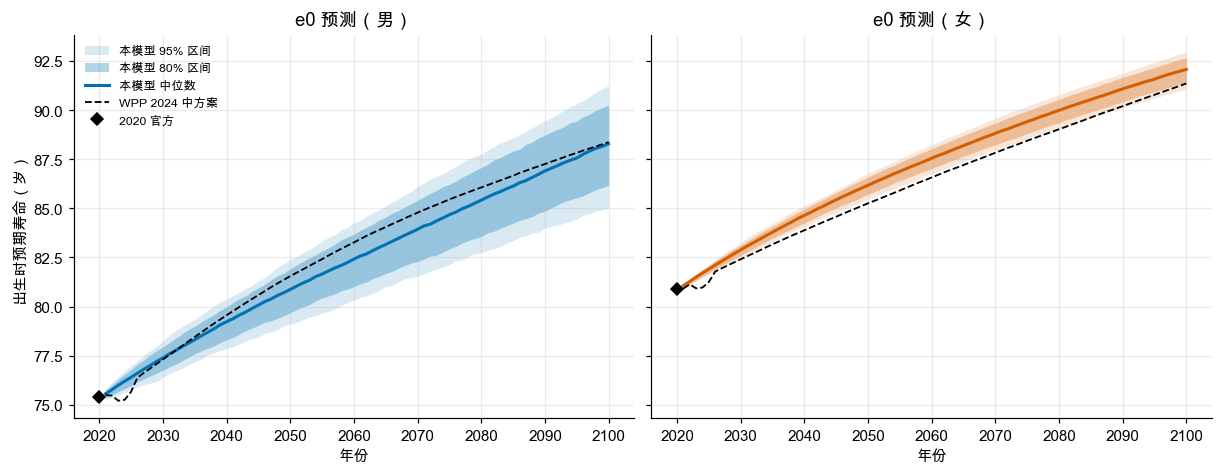

,男 p2.5,男 p50,男 p97.5,女 p2.5,女 p50,女 p97.5
2030,76.4,77.4,78.3,82.5,82.9,83.3
2050,79.1,80.9,82.4,85.5,86.2,86.8
2070,81.5,83.9,86.1,88.0,88.8,89.6
2100,85.0,88.3,91.2,91.1,92.1,93.0


In [8]:
H = 80
years = np.arange(2021, 2021 + H)
forecast = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, sex in zip(axes, ("male", "female")):
    base = np.log(adj[2020]["mx"][sex].loc[LC_AGES])
    m = replace(lc_models[sex], jump_off=base)
    sims = leecarter.e0_paths(m, sex, H, n_sims=N_SIMS, seed=SEED)
    forecast[sex] = percentiles(sims, years)
    fan(ax, forecast[sex], SEX_STYLE[sex]["color"], "本模型")
    wpp_e0 = wpp.indicators()[{"male": "LExMale", "female": "LExFemale"}[sex]].loc[2021:2100]
    ax.plot(wpp_e0.index, wpp_e0, color=COLORS["black"], ls="--", lw=1.2, label="WPP 2024 中方案")
    ax.plot(2020, official.LIFE_EXPECTANCY[2020][sex], "D", color=COLORS["black"], label="2020 官方")
    ax.set(title=f"e0 预测（{SEX_STYLE[sex]['label']}）", xlabel="年份")
axes[0].set_ylabel("出生时预期寿命（岁）")
axes[0].legend(fontsize=8, loc="upper left")
plt.show()
pd.DataFrame({f"{SEX_STYLE[s]['label']} {c}": forecast[s].loc[[2030, 2050, 2070, 2100], c] for s in ("male", "female") for c in ("p2.5", "p50", "p97.5")}).round(1)

再看与债券模型直接相关的两个量：**活到 65 岁的比例**（能“进入兑付期”的人）和 **65 岁余寿**（兑付期长度）。这里用中位路径计算：

In [9]:
H = 80
rows = []
for sex in ("male", "female"):
    m = replace(lc_models[sex], jump_off=np.log(adj[2020]["mx"][sex].loc[LC_AGES]))
    med = leecarter.forecast_log_m(m, H)
    for h, year in enumerate(np.arange(2021, 2021 + H)):
        if year in (2030, 2050, 2070, 2100):
            mx = lifetable.kannisto_close(pd.Series(np.exp(med[h]), index=LC_AGES), fit_ages=range(80, 90))
            lt = lifetable.life_table(mx, sex)
            rows.append({"性别": SEX_STYLE[sex]["label"], "年份": year, "e0": lt.loc[0, "ex"], "活到65岁比例": lt.loc[65, "lx"], "e65（兑付期长度）": lt.loc[65, "ex"]})
pd.DataFrame(rows).set_index(["性别", "年份"]).round(3)

e0  活到65岁比例  e65（兑付期长度）
性别 年份                               
男  2030  77.373    0.838      17.294
   2050  80.858    0.884      19.459
   2070  83.963    0.915      21.686
   2100  88.275    0.947      25.101
女  2030  82.878    0.929      20.365
   2050  86.173    0.958      22.644
   2070  88.834    0.975      24.734
   2100  92.075    0.989      27.511

## 小结

| 环节 | 旧模型 | 新模型 |
|---|---|---|
| 存活率 | $1-D/P$，截断在 0.90–0.9999 | 标准生命表，0 岁用 Andreev–Kingkade $a_0$ |
| 数据质量 | 直接用普查（e0 高估约 4 岁） | 校正到官方 IMR、U5MR、e0 |
| 高龄 | 100 岁固定存活率 0.90/0.92 | Kannisto 平滑，延伸到 110 岁 |
| 未来 | 不变 | Lee–Carter 随机游走，蒙特卡洛 500 条路径 |
| 不确定性 | 无 | 80%/95% 预测区间，经回测检验 |

> **对导师怎么说**：死亡模块改用标准生命表和 Lee–Carter 随机死亡率模型。起点是经官方指标校正后的 2020 年普查死亡率，
> 改善速度从 WPP 1990–2019 年单岁死亡率中估计（第一主成分解释约 97% 的变化）。回测显示，用 2009 年以前的数据预测 2010–2019 年 e0，
> 误差在 0.1 岁量级且全部落入 95% 区间；但模型无法预见新冠这类冲击，且区间偏窄，后续用情景分析补充。
> 预测显示 65 岁余寿（养老“兑付期”）将持续延长，这是养老压力上升的独立来源，与生育率下降叠加。